In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent    # notebooks -> project_root
sys.path.insert(0, str(project_root))
print(project_root)

import math 
import pyvista
from matplotlib import pyplot as plt

import numpy as np

from FenicsxModels import PoissonSolvers, FenicsxPriors, Helpers
from FenicsxModels.Testing import testPoissonConvergence, testPoissonAdjoint
import importlib


/Users/tcui0786/Work/DeepTransport/PyFInS


In [2]:
importlib.reload(PoissonSolvers)
importlib.reload(testPoissonConvergence)
importlib.reload(FenicsxPriors)

#print("mpi4py size:", MPI.COMM_WORLD.size, "rank:", MPI.COMM_WORLD.rank)
#print("petsc comm size:", PETSc.COMM_WORLD.getSize(), "rank:", PETSc.COMM_WORLD.getRank())

testPoissonConvergence.test_poisson_convergence(order=1, const_k=True)
testPoissonConvergence.test_poisson_convergence(order=2, const_k=False)


       N                  L2                  H1                 QoI         Observation
--------------------------------------------------------------------------------------------
       8        2.142927e-02        3.305243e-01        8.504410e-03        1.504219e-01
      16        5.669369e-03        1.654395e-01        2.142584e-03        3.923126e-02
      32        1.440123e-03        8.252450e-02        5.354936e-04        1.031174e-02
      64        3.615262e-04        4.122742e-02        1.338517e-04        2.578296e-03
     128        9.035230e-05        2.060899e-02        3.337508e-05        6.035710e-04

Convergence rates
--------------------------------------------------------------------------------------------
L2                  : 1.918  1.977  1.994  2.000
H1                  : 0.998  1.003  1.001  1.000
QoI                 : 1.989  2.000  2.000  2.004
Observation         : 1.939  1.928  2.000  2.095
----------------------------------------------------------------

/var/folders/35/sjd32gz17sdgbnzs84sr2kb80000gp/T/ipykernel_41836/657178856.py:40: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


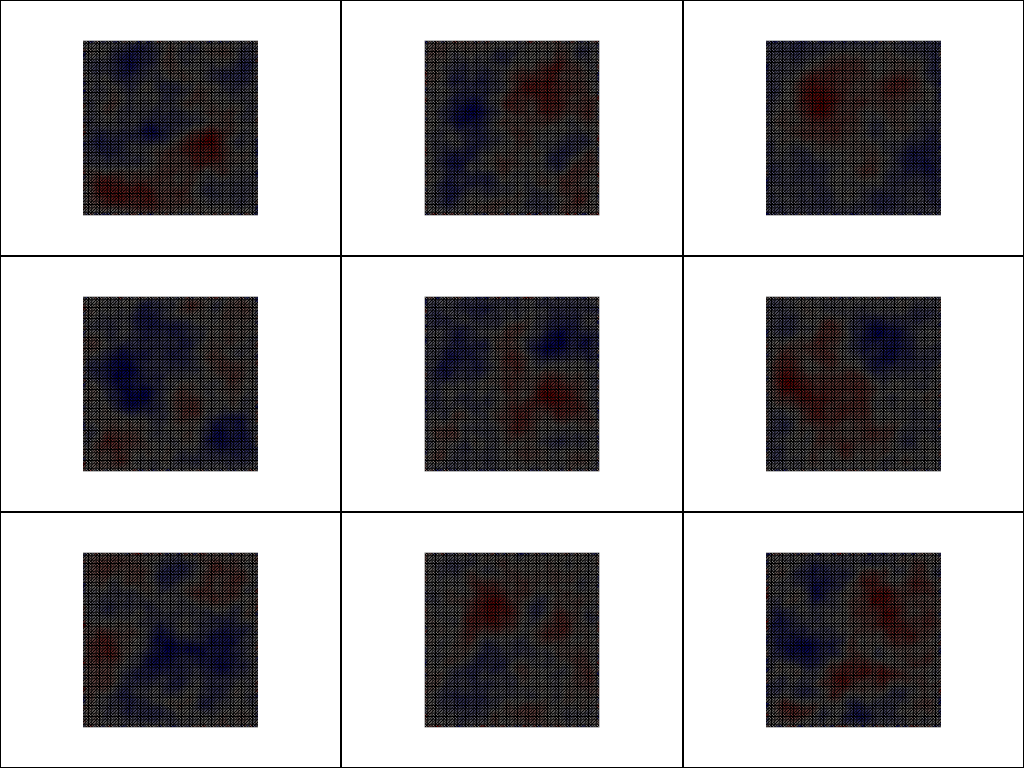

In [3]:
from dolfinx import fem

# mesh size
Nx = 64
Ny = 64
corner_points=((0.0, 0.0), (2.0, 2.0))

# Dirichlet data
def gL(y): return 1.0 + 0.5*y
def gR(y): return - np.sin(2.0*np.pi*y) - 1.0

# observation grid
obs_n_grid = 7
obs_eps = 4.0/Nx

fem1 = PoissonSolvers.PoissonCG(corner_points, Nx, Ny, gL, gR, order=1, const_k=True, log_normal=True)
fem1.make_observation_operator(obs_n_grid, obs_eps)
prior1 = FenicsxPriors.PriorSPDE(fem1.Kh, sigma = 1, ell = 1.0, mu = 0.0)

# plot prior draws
n_draws = 9
prior_samples = prior1.sample(n_draws)

#pyvista.set_jupyter_backend("static")

ncols = math.ceil(math.sqrt(n_draws))
nrows = math.ceil(n_draws / ncols)
plotter = pyvista.Plotter(shape=(nrows, ncols))

for k in range(n_draws):
    i, j = divmod(k, nrows)
    plotter.subplot(i, j)
    phi = fem.Function(prior1.Kh)
    phi.x.array[:] = prior_samples[k,:]
    phi.x.scatter_forward()
    plot_grid = Helpers.plotting_grid(phi)
    plotter.add_mesh(plot_grid, show_edges=True, show_scalar_bar=False, cmap="bwr")
    plotter.view_xy()

plotter.show()




/var/folders/35/sjd32gz17sdgbnzs84sr2kb80000gp/T/ipykernel_41836/521322791.py:11: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install "pyvista[jupyter]"
  plotter.show()


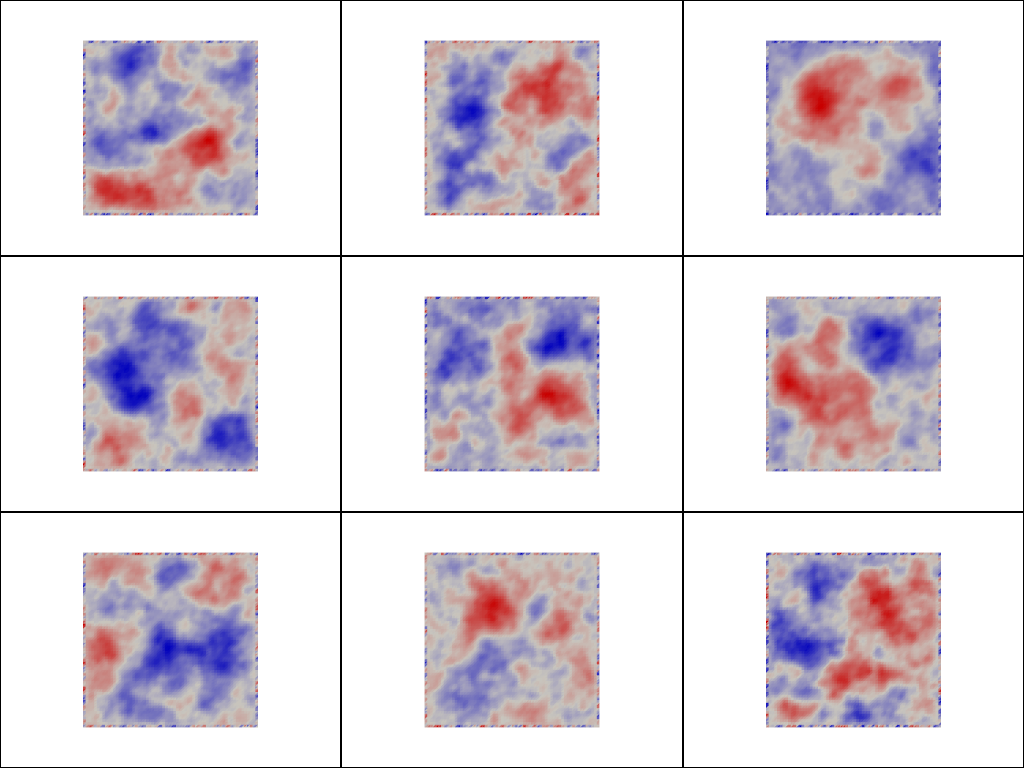

In [5]:

for k in range(n_draws):
    i, j = divmod(k, nrows)
    plotter.subplot(i, j)
    phi = fem.Function(prior1.Kh)
    phi.x.array[:] = prior_samples[k,:]
    phi.x.scatter_forward()
    plot_grid = Helpers.plotting_grid(phi)
    plotter.add_mesh(plot_grid, show_edges=False, show_scalar_bar=False, cmap="bwr")
    plotter.view_xy()

plotter.show()

In [6]:
import time

t_total = 0.0
for k in range(n_draws):
    t0 = time.perf_counter()
    y, Q = fem1.solve_and_cache(prior_samples[k])
    t_total = t_total + (time.perf_counter() - t0)

print(t_total/n_draws)



0.027533898220604494


In [7]:

%load_ext line_profiler
%lprun -f fem1.solve fem1.solve(np.exp(prior_samples[k]))

Timer unit: 1e-09 s

Total time: 0.026018 s
File: /Users/tcui0786/Work/DeepTransport/PyFInS/FenicsxModels/PoissonSolvers.py
Function: PoissonCG.solve at line 258

Line #      Hits         Time  Per Hit   % Time  Line Contents
   258                                               def solve(self, k_in):
   259                                                   # x = ufl.SpatialCoordinate(self.mesh)
   260                                                   # k as a Function
   261                                           
   262         1       2000.0   2000.0      0.0          if self.log_normal:
   263         1     136000.0 136000.0      0.5              k_fun = coerce_space_value(np.exp(k_in), self.Kh)
   264                                                   else:
   265                                                       k_fun = coerce_space_value(k_in, self.Kh)
   266                                           
   267         1     567000.0 567000.0      2.2          a = ufl.inner(k_

In [8]:
%lprun -f fem1.linearized_observation_transpose fem1.linearized_observation_transpose(y)

Timer unit: 1e-09 s

Total time: 0.216242 s
File: /Users/tcui0786/Work/DeepTransport/PyFInS/FenicsxModels/PoissonSolvers.py
Function: PoissonCG.linearized_observation_transpose at line 504

Line #      Hits         Time  Per Hit   % Time  Line Contents
   504                                               def linearized_observation_transpose(self, delta_y):
   505                                                   """
   506                                                   """
   507                                                   #lam = self._adjoint_observation(delta_y)
   508                                                   #density_ufl = -ufl.inner(ufl.grad(self.p_h), ufl.grad(lam))
   509                                                   #return self._grad_k(density_ufl)
   510                                           
   511         1       4000.0   4000.0      0.0          arr = np.asarray(delta_y, dtype=np.float64)    
   512         1       1000.0   1000.0      0.0         

In [9]:
for k in range(n_draws):
    r = prior1.random()
    xV = prior1._solve_A(prior1.sqrtM * r)
    xK = prior1._CG1_to_DG0_coef(xV)
    uV = prior1._DG0_to_CG1_coef(xK)
    print(np.linalg.norm(uV - xV))

print(fem1.C_local.shape[0])

25.14733368228869
35.347339198577984
38.869773562095325
33.263062385541346
33.097114377163514
42.88782713742506
36.64477907527164
32.99187273188165
30.888364057357975
49


In [10]:
importlib.reload(testPoissonAdjoint)

testPoissonAdjoint.test_poisson_adjoint(const_k=False, N=32, order=1)


Poisson const_k=False, N=32, order=1: 10 realisations, MPI=1
------------------------------------------------------------------------------------------------------------
test                               min error        mean error         max error         tolerance    passed
------------------------------------------------------------------------------------------------------------
prior_adjoint                   3.292777e-16      2.078535e-15      7.967703e-15      1.000000e-10      True
prior_inverse                   5.467988e-16      6.410661e-16      7.133772e-16      1.000000e-10      True
physical_derivative             3.939427e-07      7.138233e-06      3.662301e-05      1.000000e-05      True
physical_adjoint                0.000000e+00      2.706561e-15      1.788455e-14      1.000000e-10      True
whitened_derivative             3.297632e-07      3.121609e-06      1.414389e-05      1.000000e-05      True
whitened_adjoint                0.000000e+00      2.242486e-15    